# Testing LIWC significance
This notebook will test if the LIWC sentiment has anything to do with the link sentiment or if they are independent.
We will run this experiment for both title and body independently as well as for the compound case  

In [ ]:
import sys, os
sys.path.append(os.path.join(os.getcwd(), '..', '..'))
from utils.data_utils import load_enhanced_df

df = load_enhanced_df()

df.loc[df["LINK_SENTIMENT"] == -1, "LINK_SENTIMENT"] = 0
df["LINK_SENTIMENT"] = df["LINK_SENTIMENT"].astype(int)

In [16]:
import pandas as pd

df['Sentiment_compound_vader'] = pd.to_numeric(df['Sentiment_compound_vader'], errors='coerce')
body_df = df[df["source_type"] == "body"]
title_df = df[df["source_type"] == "title"]

print(body_df.shape, title_df.shape)


(286561, 183) (571927, 183)


In [22]:
import statsmodels.formula.api as smf
import statsmodels.api as sm
import numpy as np

mod_b = smf.logit("LINK_SENTIMENT ~ Sentiment_compound_vader", data=body_df).fit()
mod_t = smf.logit("LINK_SENTIMENT ~ Sentiment_compound_vader", data=title_df).fit()

print(mod_b.summary())
print(mod_t.summary())

Optimization terminated successfully.
         Current function value: 0.249160
         Iterations 7
Optimization terminated successfully.
         Current function value: 0.270301
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:         LINK_SENTIMENT   No. Observations:               286561
Model:                          Logit   Df Residuals:                   286559
Method:                           MLE   Df Model:                            1
Date:                Mon, 03 Nov 2025   Pseudo R-squ.:                 0.05143
Time:                        10:59:06   Log-Likelihood:                -71400.
converged:                       True   LL-Null:                       -75271.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                               coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------

In [28]:
w_b = body_df['LINK_SENTIMENT'].map(
    body_df['LINK_SENTIMENT'].value_counts(normalize=True).rdiv(1)
)
glm_b = smf.glm(
    'LINK_SENTIMENT ~ Sentiment_compound_vader',
    data=body_df,
    family=sm.families.Binomial(),
    freq_weights=w_b
).fit()
print(glm_b.summary())

w_t = title_df['LINK_SENTIMENT'].map(
    title_df['LINK_SENTIMENT'].value_counts(normalize=True).rdiv(1)
)
glm_t = smf.glm(
    'LINK_SENTIMENT ~ Sentiment_compound_vader',
    data=title_df,
    family=sm.families.Binomial(),
    freq_weights=w_t
).fit()
print(glm_t.summary())

w = df['LINK_SENTIMENT'].map(
    df['LINK_SENTIMENT'].value_counts(normalize=True).rdiv(1)
)
glm = smf.glm(
    'LINK_SENTIMENT ~ Sentiment_compound_vader',
    data=df,
    family=sm.families.Binomial(),
    freq_weights=w
).fit()
print(glm.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:         LINK_SENTIMENT   No. Observations:               286561
Model:                            GLM   Df Residuals:                573120.00
Model Family:                Binomial   Df Model:                            1
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:            -3.7063e+05
Date:                Mon, 03 Nov 2025   Deviance:                   7.4127e+05
Time:                        11:09:20   Pearson chi2:                 5.73e+05
No. Iterations:                     5   Pseudo R-squ. (CS):             0.1696
Covariance Type:            nonrobust                                         
                               coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------
Intercept               

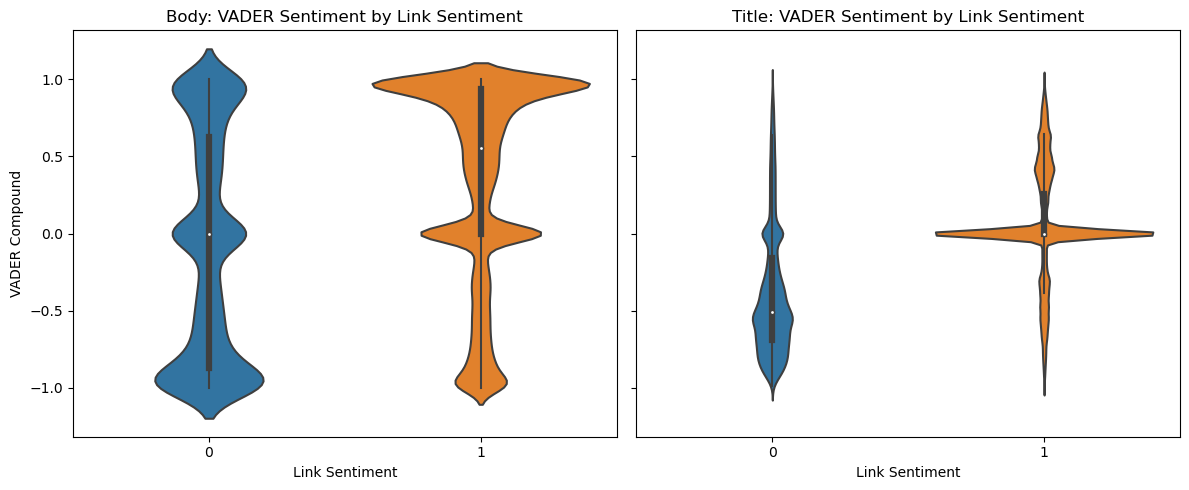

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns
from src.utils.data_utils import load_enhanced_df
import pandas as pd

def draw_violin_plots():    
    df = load_enhanced_df()

    df.loc[df["LINK_SENTIMENT"] == -1, "LINK_SENTIMENT"] = 0
    df["LINK_SENTIMENT"] = df["LINK_SENTIMENT"].astype(int)

    df['Sentiment_compound_vader'] = pd.to_numeric(df['Sentiment_compound_vader'], errors='coerce')
    body_df = df[df["source_type"] == "body"]
    title_df = df[df["source_type"] == "title"]


    _, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

    sns.violinplot(
        data=body_df,
        x='LINK_SENTIMENT', 
        y='Sentiment_compound_vader',
        inner='box',
        ax=axes[0]
    )
    axes[0].set_title('Body: VADER Sentiment by Link Sentiment')
    axes[0].set_xlabel('Link Sentiment')
    axes[0].set_ylabel('VADER Compound')

    sns.violinplot(
        data=title_df,
        x='LINK_SENTIMENT', 
        y='Sentiment_compound_vader',
        inner='box',
        ax=axes[1]
    )
    axes[1].set_title('Title: VADER Sentiment by Link Sentiment')
    axes[1].set_xlabel('Link Sentiment')
    axes[1].set_ylabel('')

    plt.tight_layout()
    plt.show()

draw_violin_plots()